# Neural network with PyTorch

As a last step we train neural networks on the same preprocessed features and compare them with the random forest tuned in [`07_hyperparameter_tuning.ipynb`](07_hyperparameter_tuning.ipynb), which reached a cross-validation RMSE of about 41,604 USD. The PyTorch basics (tensors, `Dataset`/`DataLoader`, the training loop) are covered in the [PyTorch notes of the course](https://github.com/avidaldo/ia25/tree/master/pytorch); here we only apply them.

## Initial setup

In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

In [ ]:
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Use the GPU if available, otherwise the CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed(RANDOM_STATE)  # seed for the GPU
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

num_workers = os.cpu_count() // 2  # half of the available cores, a common heuristic

Using device: cuda


## Data loading

Besides the usual training and test sets, we separate a **validation set** from the training data to monitor the networks during training. For simplicity, we won't perform *cross-validation*, since it is less common in *deep learning* because larger amounts of data are typically used for training, which increases computational cost. However, in this case, the dataset isn't that large and it would be feasible (see [Cross-validation](../notes/cross_validation.ipynb)).

In [ ]:
from utils.load_california import load_housing_data

VAL_SIZE = 0.2

X_train_full, X_test, y_train_full, y_test = load_housing_data()

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=VAL_SIZE, random_state=RANDOM_STATE
)

## Data preprocessing

The preprocessing pipeline is imported from [`utils/housing_preprocessing.py`](utils/housing_preprocessing.py) with the number of clusters found in the hyperparameter search (76). The pipeline must be **fitted** *only* with the **training** data (`X_train`) to avoid information leakage; then it is used to **transform** the other sets (see [Data leakage](../notes/data_leakage.ipynb)).

In [ ]:
from utils.housing_preprocessing import get_preprocessing_pipeline

preprocessing_pipeline = get_preprocessing_pipeline(n_clusters=76)

# Fit the pipeline ONLY with training data
preprocessing_pipeline.fit(X_train)

# Transform the three sets
X_train_processed = preprocessing_pipeline.transform(X_train)
X_val_processed = preprocessing_pipeline.transform(X_val)
X_test_processed = preprocessing_pipeline.transform(X_test)

Feature normalization is essential for neural networks because bringing all attributes to comparable scales prevents those with larger magnitudes from dominating the gradient calculations, which accelerates the convergence of optimization algorithms and improves numerical stability by preventing overflow or "dead" gradients in the flat regions of activation functions. In this case, the preprocessing *pipeline* already standardizes the input variables.

Likewise, normalizing the target variable in regression tasks helps the cost function operate in a reasonable range, facilitates more consistent update steps during learning, and can improve both the convergence speed and the final quality of the model (see [Feature scaling](../notes/feature_scaling.ipynb#Scaling-the-target)). The `y_scaler` is kept to convert predictions back to dollars.

In [ ]:
from utils.housing_preprocessing import scale_target

y_train_scaled_np, y_val_scaled_np, y_test_scaled_np, y_scaler = scale_target(y_train, y_val, y_test)

## Loss function

The evaluation metric is the RMSE, so the networks minimize the `nn.MSELoss()` loss function: minimizing MSE is equivalent to minimizing RMSE (see [Regression metrics](../notes/regression_metrics.ipynb)). We report the RMSE, in dollars, because it is more interpretable.

In [ ]:
criterion = nn.MSELoss()

## Baseline: random forest

The reference is the random forest with the best hyperparameters found in the search (cross-validation RMSE of 41,604 USD; test RMSE of 39,217 USD), retrained here on this notebook's training split and evaluated on its validation split, so that the comparison with the networks is on the same data.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=290,
    max_depth=87,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=num_workers,
)
rf_model.fit(X_train_processed, y_train)
y_val_pred = rf_model.predict(X_val_processed)
rf_val_rmse = root_mean_squared_error(y_val, y_val_pred)

print(f"Random forest validation RMSE: {rf_val_rmse:,.0f}")

Random forest validation RMSE: 41,059


This validation RMSE is **the reference value** for the neural network models.

## Tensors and data loaders

The preprocessed NumPy arrays are converted to **PyTorch tensors**, the fundamental data structure in PyTorch. We move them to the GPU in advance, which is fine when the VRAM is enough, as with this small dataset; the standard approach, to avoid out-of-memory errors with large datasets, is to keep them on the CPU and move each batch during training.

In [ ]:
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32, device=device)
X_val_tensor = torch.tensor(X_val_processed, dtype=torch.float32, device=device)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32, device=device)

y_train_tensor = torch.tensor(y_train_scaled_np, dtype=torch.float32, device=device)
y_val_tensor = torch.tensor(y_val_scaled_np, dtype=torch.float32, device=device)
y_test_tensor = torch.tensor(y_test_scaled_np, dtype=torch.float32, device=device)

n_features = X_train_tensor.shape[1]  # number of inputs of the network
print(f"Number of input features: {n_features}")

Number of input features: 90


`TensorDataset` pairs features and labels, and `DataLoader` iterates over the dataset in *batches*, shuffling the training data in each *epoch*.

In [ ]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 512

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

## Model 1: simple MLP

A multilayer perceptron with three hidden layers and ReLU activations, trained with Adam. The training loop, which evaluates the model on the training and validation sets after every epoch, is in [`utils/training_utils.py`](utils/training_utils.py).

In [ ]:
class SimpleMLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.layer1 = nn.Linear(n_features, 128)
        self.relu1 = nn.ReLU()
        self.layer2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()
        self.layer3 = nn.Linear(64, 32)
        self.relu3 = nn.ReLU()
        self.output_layer = nn.Linear(32, 1)

    def forward(self, x):
        x = self.relu1(self.layer1(x))
        x = self.relu2(self.layer2(x))
        x = self.relu3(self.layer3(x))
        x = self.output_layer(x)
        return x

model1 = SimpleMLP(n_features).to(device)
optimizer = optim.Adam(model1.parameters(), lr=0.001)

Starting detailed training on 'cuda' for 100 epochs...


Epoch [10/100] - 0.11s | Train RMSE: 51552 | Val RMSE: 52056


Epoch [20/100] - 0.07s | Train RMSE: 48411 | Val RMSE: 50425


Epoch [30/100] - 0.11s | Train RMSE: 47117 | Val RMSE: 50914


Epoch [40/100] - 0.07s | Train RMSE: 46790 | Val RMSE: 50984


...

Epoch [60/100] - 0.07s | Train RMSE: 43059 | Val RMSE: 49750


Epoch [70/100] - 0.11s | Train RMSE: 43952 | Val RMSE: 50310


Epoch [80/100] - 0.07s | Train RMSE: 41044 | Val RMSE: 51044


Epoch [90/100] - 0.11s | Train RMSE: 40624 | Val RMSE: 50305


Epoch [100/100] - 0.07s | Train RMSE: 39817 | Val RMSE: 48929

Detailed training finished in 8.26 seconds.


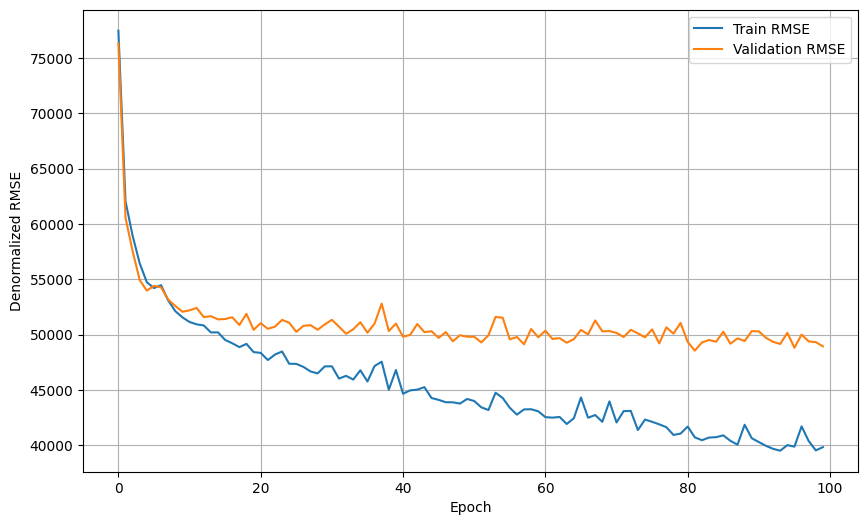

In [ ]:
from utils.training_utils import train_model_detailed, plot_metrics

num_epochs = 100

metrics1 = train_model_detailed(
    model=model1,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    y_scaler=y_scaler,
    num_epochs=num_epochs,
    device=device,
    print_every=10,  # print metrics every 10 epochs
)

plot_metrics(metrics1)

## Model 2: MLP with batch normalization and dropout

A wider network with `BatchNorm1d` after each linear layer, to stabilize training, and `Dropout`, to reduce overfitting.

In [ ]:
class Model2(nn.Module):
    def __init__(self, n_features):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.2),

            nn.Linear(64, 1)  # single-value regression output
        )

    def forward(self, x):
        return self.net(x)

model2 = Model2(n_features).to(device)
optimizer = optim.Adam(model2.parameters(), lr=0.001)

Starting detailed training on 'cuda' for 100 epochs...


Epoch [10/100] - 0.11s | Train RMSE: 51509 | Val RMSE: 51064


Epoch [20/100] - 0.07s | Train RMSE: 49762 | Val RMSE: 50594


Epoch [30/100] - 0.08s | Train RMSE: 48215 | Val RMSE: 49382


Epoch [40/100] - 0.07s | Train RMSE: 46366 | Val RMSE: 48231


...

Epoch [60/100] - 0.08s | Train RMSE: 45012 | Val RMSE: 47961


Epoch [70/100] - 0.07s | Train RMSE: 44200 | Val RMSE: 47299


Epoch [80/100] - 0.07s | Train RMSE: 43415 | Val RMSE: 47355


Epoch [90/100] - 0.07s | Train RMSE: 43225 | Val RMSE: 46787


Epoch [100/100] - 0.11s | Train RMSE: 42144 | Val RMSE: 47022

Detailed training finished in 8.83 seconds.


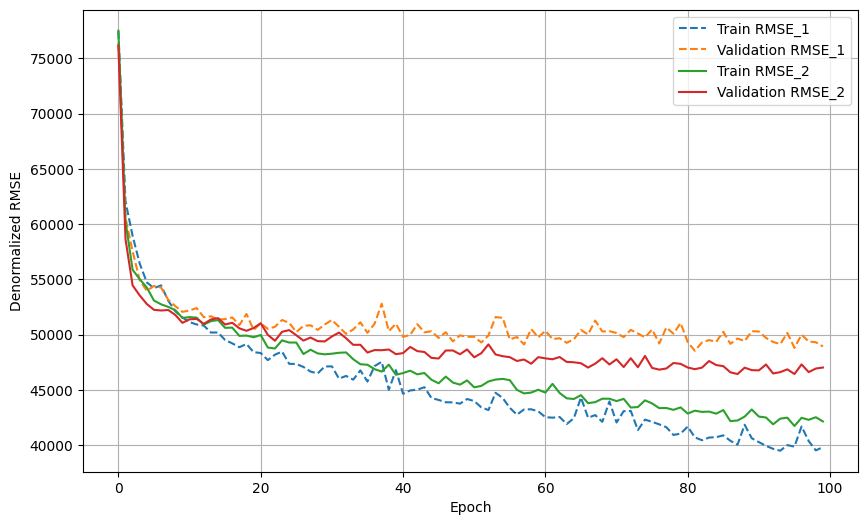

In [ ]:
metrics2 = train_model_detailed(
    model=model2,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    y_scaler=y_scaler,
    num_epochs=num_epochs,
    device=device,
    print_every=10,
)

plot_metrics(metrics1, metrics2)

## Comparison

In [ ]:
from utils.training_utils import evaluate_model

print(f"Random forest  validation RMSE: {rf_val_rmse:,.0f}")
print(f"Model 1 (MLP)  validation RMSE: {evaluate_model(model1, val_loader, criterion, y_scaler, device)[0]:,.0f}")
print(f"Model 2 (BN+DO) validation RMSE: {evaluate_model(model2, val_loader, criterion, y_scaler, device)[0]:,.0f}")

Random forest  validation RMSE: 41,059
Model 1 (MLP)  validation RMSE: 48,929
Model 2 (BN+DO) validation RMSE: 47,022


Neither network improves on the random forest's reference RMSE. It should be noted, however, that the random forest underwent hyperparameter tuning with *cross-validation*, while the neural networks have not been tuned: the architecture, learning rate, batch size and number of epochs were chosen by hand.